# Collaborative Filtering

## Thư viện

In [48]:
import os
import json
import glob
import shutil
from datetime import datetime
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import torch.nn as nn 
import time


In [49]:
print(f"PyTorch version: {torch.__version__}")
print(f"PyTorch CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.14.1+cpu
PyTorch CUDA available: False


In [50]:
def set_all_seeds(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    

set_all_seeds(42)
print(f"Set random seed to 42 for reproducibility.")


Set random seed to 42 for reproducibility.


In [ ]:
# utils print epochs result

def print_per_epoch(
    epoch: int,
    epochs: int,
    pairs: dict[str, float]
):
    """In kết quả train theo epoch

    Args:
        epoch (int): epoch hiện tại
        epochs (int): tổng epochs
        pairs (dict[str, float]): Các chỉ số và giá trị tương ứng
    """
    postfix = " | ".join([f"{name}: {mse:.4f}" for name, mse in pairs.items()])
    print(f"Epoch {epoch}/{epochs} | {postfix}")
    
print_per_epoch(1, 10, {"Train MSE": 0.1234, "Val MSE": 0.2345})

Epoch 1/10 | Train MSE: 0.1234 | Val MSE: 0.2345


## Cấu hình

In [52]:
class Config:
    # Paths
    DATA_DIR = Path("../data")
    FINAL_DATA_DIR = DATA_DIR / "final_data"
    ARTIFACT_DIR = DATA_DIR / "artifacts"
    CF_DIR = ARTIFACT_DIR / "cf"
    PARQUET_DIR = DATA_DIR / "interactions_parquet"
    
    RATINGS_PATH = FINAL_DATA_DIR / "ratings_filtered_by_movie.csv" 
    
    
    # Data Schema
    USER_COL = "userId"
    MOVIE_COL = "movieId"
    RATING_COL = "rating"
    TIMESTAMP_COL = "timestamp"
    
    # Lọc và Chia tập (Top N mới nhất)
    MAX_ROWS_TO_PROCESS = 1_000_000
    TRAIN_RATIO = 0.8
    VAL_RATIO = 0.1
    TEST_RATIO = 0.1
    
    # Hyperparameters
    EMBEDDING_DIM = 64
    INIT_STD = 0.01
    BATCH_SIZE = 1024 
    CHUNK_SIZE = 500000 
    EPOCHS = 10
    LEARNING_RATE = 0.002
    WEIGHT_DECAY = 1e-4
    DROPOUT_RATE = 0.2
    
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    
    # Tiền tố Versioning bằng Timestamp
    RUN_TIMESTAMP = f"{datetime.now().strftime('%Y%m%d_%H%M%S')}_{1_000_000}"
    # RUN_TIMESTAMP = '20261019_124842_1000000'
    
    TOP_K = 10  # Số lượng đề xuất hàng đầu cho mỗi người dùng
    RELEVANCE_THRESHOLD = 4.0  # Rating >= ngưỡng này được xem là phim relevant
    RANDOM_STATE = 42
    
    @classmethod
    def setup(cls):
        cls.PARQUET_DIR.mkdir(parents=True, exist_ok=True)
        cls.CF_DIR.mkdir(parents=True, exist_ok=True)
        os.makedirs(cls.ARTIFACT_DIR, exist_ok=True)
        (cls.PARQUET_DIR / "train").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "val").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "test").mkdir(exist_ok=True)
        print(f"[INFO] Target Device: {cls.DEVICE}")
        print(f"[INFO] Training Run ID: {cls.RUN_TIMESTAMP}")

Config.setup()


[INFO] Target Device: cpu
[INFO] Training Run ID: 20261019_233722_1000000


## Xử lý dữ liệu

In [53]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# PAPER-STYLE PREPROCESSING (NCF - He et al. 2017)
# - Rating → binary 1 (implicit signal, như paper)
# - Filter user ≥ 20 interactions
# - Split LOO (Leave-One-Out)
# ============================================================

def preprocess_paper_style(
    csv_path,
    user_col='userId',
    movie_col='movieId',
    rating_col='rating',
    timestamp_col='timestamp',
    max_rows=1_000_000,
    min_interactions=20,
    chunk_size=200_000,
    verbose=True,
):
    """Pipeline chuẩn paper NCF."""
    
    # ---- BƯỚC 1: Chunked read, giữ top-N mới nhất ----
    if verbose: print(f"[1/5] Reading top {max_rows:,} newest interactions...")
    recent = pd.DataFrame()
    for chunk in pd.read_csv(
        csv_path,
        usecols=[user_col, movie_col, rating_col, timestamp_col],
        chunksize=chunk_size,
    ):
        recent = pd.concat([recent, chunk], ignore_index=True)
        recent = recent.nlargest(max_rows, timestamp_col)
    
    recent = recent.dropna(subset=[user_col, movie_col, rating_col, timestamp_col])
    if verbose: print(f"      Loaded {len(recent):,} rows, {recent[user_col].nunique():,} users, "
                      f"{recent[movie_col].nunique():,} items")
    
    # ---- BƯỚC 2: Stats trước filter ----
    user_counts = recent[user_col].value_counts()
    if verbose:
        print(f"[2/5] Before filter (per-user stats):")
        print(f"      min={user_counts.min()} | median={user_counts.median():.0f} | "
              f"max={user_counts.max()} | mean={user_counts.mean():.1f}")
        print(f"      Users with ≥{min_interactions}: {(user_counts >= min_interactions).sum():,} "
              f"({(user_counts >= min_interactions).mean()*100:.1f}%)")
    
    # ---- BƯỚC 3: Filter user ≥ min_interactions (paper) ----
    users_keep = user_counts[user_counts >= min_interactions].index
    df = recent[recent[user_col].isin(users_keep)].copy()
    if verbose: print(f"[3/5] After filter: {len(df):,} rows, {len(users_keep):,} users")
    
    # ---- BƯỚC 4: Binarize + Sort + Mapping ----
    # Paper: mọi rating đều thành 1 (chỉ cần "user đã tương tác")
    df['label'] = 1
    
    # Sort tie-break bằng movieId để đảm bảo deterministic
    df = df.sort_values(
        [user_col, timestamp_col, movie_col], kind='stable'
    ).reset_index(drop=True)
    
    user_mapping = {str(u): i for i, u in enumerate(df[user_col].unique())}
    movie_mapping = {str(m): i for i, m in enumerate(df[movie_col].unique())}
    df['user_idx'] = df[user_col].astype(str).map(user_mapping)
    df['movie_idx'] = df[movie_col].astype(str).map(movie_mapping)
    if verbose: print(f"[4/5] Mapping done: {len(user_mapping):,} users, {len(movie_mapping):,} items")
    
    # ---- BƯỚC 5: LOO split ----
    train_parts, val_parts, test_parts = [], [], []
    for uid, group in df.groupby('user_idx', sort=False):
        n = len(group)
        # Guaranteed n >= 20 by filter
        train_parts.append(group.iloc[:-2])
        val_parts.append(group.iloc[-2:-1])
        test_parts.append(group.iloc[-1:])
    
    train_df = pd.concat(train_parts, ignore_index=True)
    val_df = pd.concat(val_parts, ignore_index=True)
    test_df = pd.concat(test_parts, ignore_index=True)
    
    # ---- Report cuối ----
    if verbose:
        print(f"[5/5] Split summary:")
        print(f"      Train: {len(train_df):,} rows | {train_df['user_idx'].nunique():,} users")
        print(f"      Val:   {len(val_df):,} rows | {val_df['user_idx'].nunique():,} users")
        print(f"      Test:  {len(test_df):,} rows | {test_df['user_idx'].nunique():,} users")
        sparsity = 1 - len(df) / (len(user_mapping) * len(movie_mapping))
        print(f"      Sparsity: {sparsity:.4%}")
        print(f"      Coverage: 100% (all filtered users evaluated)")
    
    return train_df, val_df, test_df, user_mapping, movie_mapping


# ============================================================
# CHẠY
# ============================================================
train_df, val_df, test_df, user_mapping, movie_mapping = preprocess_paper_style(
    csv_path=Config.RATINGS_PATH,
    user_col=Config.USER_COL,
    movie_col=Config.MOVIE_COL,
    rating_col=Config.RATING_COL,
    timestamp_col=Config.TIMESTAMP_COL,
    max_rows=Config.MAX_ROWS_TO_PROCESS,     
    min_interactions=20,
)


# ---------- 2. ĐỌC MAPPING để lấy num_users / num_movies ----------
# A. Khởi tạo đường dẫn động (Version bằng Timestamp)
dir_path_with_timestamp: Path =  Config.CF_DIR / Config.RUN_TIMESTAMP
os.makedirs(dir_path_with_timestamp, exist_ok=True)

def get_timestamped_path(base_dir: Path, postfix_filename: str) -> Path:
    """
    Tạo đường dẫn tệp với tiền tố timestamp.
    
    Args:
        base_dir (Path): Thư mục cơ sở để lưu tệp.
        postfix_filename (str): Tên tệp gốc.
        
    Returns:
        Path: Đường dẫn tệp mới với tiền tố timestamp.
    """
    return base_dir / f"{Config.RUN_TIMESTAMP}_{postfix_filename}"

num_users  = len(user_mapping)
num_movies = len(movie_mapping)

# ---------- 3. BIẾN DÙNG CHUNG ----------
DEVICE       = torch.device(Config.DEVICE)
RATING_COL   = Config.RATING_COL
USER_COL_IDX = "user_idx"
MOVIE_COL_IDX = "movie_idx"
TOP_K        = Config.TOP_K
RUN_ID       = Config.RUN_TIMESTAMP

# ---------- 4. IN RA ĐỂ VERIFY ----------
print("=" * 60)
print(f"TRAIN: {len(train_df):>9,} rows | users={train_df['user_idx'].nunique():>6,}")
print(f"VAL:   {len(val_df):>9,} rows | users={val_df['user_idx'].nunique():>6,}")
print(f"TEST:  {len(test_df):>9,} rows | users={test_df['user_idx'].nunique():>6,}")
print(f"num_users={num_users:,} | num_movies={num_movies:,} | device={DEVICE}")
print(f"rating range: [{train_df[RATING_COL].min()}, {train_df[RATING_COL].max()}]")
print("=" * 60)

[1/5] Reading top 1,000,000 newest interactions...


      Loaded 1,000,000 rows, 62,683 users, 2,583 items
[2/5] Before filter (per-user stats):
      min=1 | median=7 | max=1554 | mean=16.0
      Users with ≥20: 13,140 (21.0%)
[3/5] After filter: 697,358 rows, 13,140 users
[4/5] Mapping done: 13,140 users, 2,557 items
[5/5] Split summary:
      Train: 671,078 rows | 13,140 users
      Val:   13,140 rows | 13,140 users
      Test:  13,140 rows | 13,140 users
      Sparsity: 97.9245%
      Coverage: 100% (all filtered users evaluated)
TRAIN:   671,078 rows | users=13,140
VAL:      13,140 rows | users=13,140
TEST:     13,140 rows | users=13,140
num_users=13,140 | num_movies=2,557 | device=cpu
rating range: [0.5, 5.0]


## Các hàm đánh giá

In [54]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.sparse import csr_matrix
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------- Seen items map (dùng cho TẤT CẢ model) ----------
def build_seen_map(df: pd.DataFrame) -> dict:
    """user_idx -> set(movie_idx) đã tương tác."""
    return df.groupby("user_idx")["movie_idx"].apply(set).to_dict()

TRAIN_SEEN = build_seen_map(train_df)

# ---------- Metrics ----------
def _precision_recall(recs, rel, k):
    hits = len(set(recs[:k]) & rel)
    p = hits / k
    r = hits / len(rel) if rel else 0.0
    return p, r

def _f1(p, r):
    return 2*p*r/(p+r) if (p+r) else 0.0

def _hit_rate(recs, rel, k):
    return 1.0 if set(recs[:k]) & rel else 0.0

def _ndcg(recs, rel, k):
    dcg = sum(1/np.log2(r+2) for r, m in enumerate(recs[:k]) if m in rel)
    idcg = sum(1/np.log2(r+2) for r in range(min(len(rel), k)))
    return dcg/idcg if idcg else 0.0

def _mrr(recs, rel):
    for r, m in enumerate(recs):
        if m in rel: return 1.0/(r+1)
    return 0.0

def _map(recs, rel):
    if not rel: return 0.0
    hits, s = 0, 0.0
    for r, m in enumerate(recs):
        if m in rel:
            hits += 1
            s += hits/(r+1)
    return s/len(rel)

# ---------- Fair Evaluation: tất cả model đều filter seen ----------
def evaluate_recommender(model, eval_df: pd.DataFrame, train_df: pd.DataFrame,
                          k: int = 10, verbose: bool = True) -> dict:
    """
    Đánh giá công bằng: với mỗi user trong eval_df,
    gọi model.recommend(user_idx, seen_items, k) để lấy top-K,
    rồi tính metric so với relevant items trong eval_df.
    """
    seen_map = build_seen_map(train_df)
    rows = []
    for uid, grp in eval_df.groupby("user_idx"):
        uid = int(uid)
        rel = set(grp["movie_idx"].values)
        seen = seen_map.get(uid, set())
        recs = model.recommend(uid, seen, k)
        p, r = _precision_recall(recs, rel, k)
        rows.append({
            "precision@k": p, "recall@k": r, "f1@k": _f1(p, r),
            "hit_rate@k": _hit_rate(recs, rel, k),
            "ndcg@k": _ndcg(recs, rel, k),
            "mrr@k": _mrr(recs, rel),
            "map@k": _map(recs, rel),
        })
    result = {m: float(np.mean([row[m] for row in rows])) for m in rows[0]}
    result["k"] = k
    result["n_users"] = len(rows)
    if verbose:
        print(f"  Users={len(rows)} | P@{k}={result['precision@k']:.4f} "
              f"| R@{k}={result['recall@k']:.4f} | NDCG@{k}={result['ndcg@k']:.4f} "
              f"| HR@{k}={result['hit_rate@k']:.4f}")
    return result

# ============================================================
# HÀM ĐÁNH GIÁ CHUẨN PAPER NCF
# Protocol: 1 positive + 99 sampled negatives = 100 candidates
# Từ: github.com/hexiangnan/neural_collaborative_filtering (evaluate.py)
# ============================================================

def evaluate_recommender_100cands(
    model, eval_df, train_df, num_items,
    k=10, num_neg=99, seed=42, verbose=True,
):
    """
    Paper NCF protocol:
    - Với mỗi user, lấy 1 positive item từ test
    - Sample 99 negatives chưa tương tác trong train và không trùng positive
    - Score 100 candidates, rank positive
    - Đây là cách paper báo HR@10 ~0.71 trên MovieLens
    """
    seen_map = build_seen_map(train_df)
    rng = np.random.default_rng(seed)
    rows = []
    n_skipped = 0
    
    for uid, grp in eval_df.groupby("user_idx"):
        uid = int(uid)
        pos_item = int(grp["movie_idx"].iloc[0])
        seen = seen_map.get(uid, set())
        excluded = seen | {pos_item}
        
        # Sample 99 negatives
        negs = []
        attempts = 0
        max_attempts = num_neg * 20
        while len(negs) < num_neg and attempts < max_attempts:
            j = int(rng.integers(0, num_items))
            if j not in excluded and j not in negs:
                negs.append(j)
            attempts += 1
        
        if len(negs) < num_neg:
            n_skipped += 1
            continue
        
        # Score 100 candidates
        candidates = np.array([pos_item] + negs, dtype=np.int64)
        all_scores = model.predict_all(uid)
        cand_scores = all_scores[candidates]
        
        # Rank positive (nó ở vị trí 0 trong candidates)
        order = np.argsort(-cand_scores)
        rank = int(np.where(order == 0)[0][0]) + 1
        
        # Metrics (LOO — 1 relevant item)
        hit = 1.0 if rank <= k else 0.0
        rows.append({
            "precision@k": hit / k,
            "recall@k": hit,
            "hit_rate@k": hit,
            "ndcg@k": (1.0 / np.log2(rank + 1)) if rank <= k else 0.0,
            "mrr@k": (1.0 / rank) if rank <= k else 0.0,
        })
    
    result = {m: float(np.mean([r[m] for r in rows])) for m in rows[0]}
    result["k"] = k
    result["n_users"] = len(rows)
    result["n_skipped"] = n_skipped
    
    if verbose:
        print(f"  [100-cand] Users={len(rows)} (skip={n_skipped}) | "
              f"P@{k}={result['precision@k']:.4f} | "
              f"NDCG@{k}={result['ndcg@k']:.4f} | "
              f"HR@{k}={result['hit_rate@k']:.4f}")
    return result

 

print(f"[OK] Utilities loaded. Device={DEVICE}")

[OK] Utilities loaded. Device=cpu


## Mô hình Popularity Baseline

In [55]:
class PopularityBaseline:
    name = "Popularity"
    
    def __init__(self, train_df, num_movies):
        counts = train_df.groupby("movie_idx").size()
        self.ranked = counts.sort_values(ascending=False).index.values
        self.num_movies = num_movies     # ← dùng tổng từ mapping, KHÔNG phải len(counts)
    
    def predict_all(self, user_idx):
        """
        Movie không có trong train (cold item) → score = -1e9 (luôn xếp cuối).
        Movie có trong train → score = -rank (phổ biến hơn = score cao hơn).
        """
        scores = np.full(self.num_movies, -1e9, dtype=np.float32)
        for rank_pos, movie_id in enumerate(self.ranked):
            scores[int(movie_id)] = -rank_pos
        return scores
    
    def recommend(self, user_idx, seen_items, k=10):
        recs = []
        for i in self.ranked:
            if int(i) not in seen_items:
                recs.append(int(i))
                if len(recs) >= k:
                    break
        return recs


# ---------- Chạy lại ----------
set_all_seeds(42)
pop_model = PopularityBaseline(train_df, num_movies)   # ← truyền num_movies

print("[Popularity]")
pop_100  = evaluate_recommender_100cands(pop_model, test_df, train_df, num_movies, k=10)
pop_full = evaluate_recommender(pop_model, test_df, train_df, k=10, verbose=False)
print(f"  [Full rank] HR@10={pop_full['hit_rate@k']:.4f}")

[Popularity]
  [100-cand] Users=13140 (skip=0) | P@10=0.0780 | NDCG@10=0.4714 | HR@10=0.7797
  [Full rank] HR@10=0.1365


## Mô hình Bias Matrix Factorization + SGD

In [56]:
class MF_SGD(nn.Module):
    """Biased Matrix Factorization + SGD (MSE loss)."""
    name = "MF-SGD (MSE)"

    def __init__(self, num_users, num_movies, dim=64, init_std=0.01, use_sigmoid=False):
        super().__init__()
        self.user_embedding  = nn.Embedding(num_users, dim)
        self.movie_embedding = nn.Embedding(num_movies, dim)
        self.user_bias  = nn.Embedding(num_users, 1)
        self.movie_bias = nn.Embedding(num_movies, 1)
        self.global_bias = nn.Parameter(torch.zeros(1))
        self.use_sigmoid = use_sigmoid
        self.min_rating, self.max_rating = 0.5, 5.0
        nn.init.normal_(self.user_embedding.weight,  std=init_std)
        nn.init.normal_(self.movie_embedding.weight, std=init_std)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, u, m):
        ue = self.user_embedding(u)
        me = self.movie_embedding(m)
        raw = (ue * me).sum(-1) + self.user_bias(u).squeeze(-1) \
              + self.movie_bias(m).squeeze(-1) + self.global_bias
        if self.use_sigmoid:
            raw = (self.max_rating - self.min_rating) * torch.sigmoid(raw) + self.min_rating
        return raw

    @torch.no_grad()
    def predict_all(self, user_idx: int) -> np.ndarray:
        self.eval()
        num_m = self.movie_embedding.num_embeddings
        u = torch.tensor([user_idx]*num_m, dtype=torch.long, device=DEVICE)
        m = torch.arange(num_m, device=DEVICE)
        return self(u, m).cpu().numpy()

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()


def train_mf_sgd(model, train_df, val_df=None, epochs=10, batch_size=4096,
                 lr=2e-3, weight_decay=1e-5, rating_col="rating",
                 patience=3, ckpt_path="best_mf_sgd.pt"):
    """Train MF-SGD với val early stopping dựa trên Val RMSE."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    users   = torch.tensor(train_df["user_idx"].values, dtype=torch.long)
    movies  = torch.tensor(train_df["movie_idx"].values, dtype=torch.long)
    ratings = torch.tensor(train_df[rating_col].values, dtype=torch.float32)
    n = len(users)
    
    best_rmse, patience_count = float("inf"), 0
    
    # progress bar
    
    for epoch in range(1, epochs+1):
        model.train()
        perm = torch.randperm(n)
        total_loss = 0.0
        
        batch_bar = tqdm(range(0, n, batch_size), desc=f"Epoch {epoch}/{epochs} [Train]", leave=False)
        for start in batch_bar:
            idx = perm[start:start+batch_size]
            u, m, r = users[idx].to(DEVICE), movies[idx].to(DEVICE), ratings[idx].to(DEVICE)
            pred = model(u, m)
            loss = F.mse_loss(pred, r)
            opt.zero_grad(); loss.backward(); opt.step()
            
            current_loss = loss.item()
            batch_samples = len(idx)
            total_loss += current_loss * batch_samples
            
            batch_bar.set_postfix({"Loss": f"{current_loss:.4f}"})
            
        train_mse = total_loss / n
        
        # Val
        if val_df is not None and len(val_df):
            model.eval()
            with torch.no_grad():
                vu = torch.tensor(val_df["user_idx"].values, dtype=torch.long, device=DEVICE)
                vm = torch.tensor(val_df["movie_idx"].values, dtype=torch.long, device=DEVICE)
                vr = torch.tensor(val_df[rating_col].values, dtype=torch.float32, device=DEVICE)
                val_mse = 0.0
                for s in range(0, len(vu), batch_size):
                    pred = model(vu[s:s+batch_size], vm[s:s+batch_size])
                    val_mse += F.mse_loss(pred, vr[s:s+batch_size], reduction="sum").item()
                val_mse /= len(vu)
            val_rmse = np.sqrt(val_mse)
            
            print_per_epoch(epoch, epochs, {"Train MSE": train_mse, "Val RMSE": val_rmse})
            if val_rmse < best_rmse - 1e-4:
                best_rmse = val_rmse
                torch.save(model.state_dict(), ckpt_path)
                patience_count = 0
            else:
                patience_count += 1
                if patience_count >= patience:
                    print(f"  Early stop at epoch {epoch}. Best ValRMSE={best_rmse:.4f}")
                    break
        else:
            print_per_epoch(epoch, epochs, {"Train MSE": train_mse})
    
    if val_df is not None and __import__("os").path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# # ---------- Train & Test ----------
# mf_sgd = MF_SGD(num_users, num_movies, dim=64, use_sigmoid=False)
# checkpoint_path = get_timestamped_path(dir_path_with_timestamp, "best_mf_sgd.pt")
# mf_sgd = train_mf_sgd(mf_sgd, train_df, val_df, epochs=15, batch_size=4096,
#                       lr=2e-3, patience=3, ckpt_path=checkpoint_path)

# print("\n[MF-SGD] Đánh giá trên TEST:")
# mf_test = evaluate_recommender(mf_sgd, test_df, train_df, k=10)

## Mô hình Bayesian Personalized Ranking - Matrix Factorization

In [64]:
class BPR_MF(nn.Module):
    name = "BPR-MF"
    
    def __init__(self, num_users, num_movies, dim=64, init_std=0.01):
        super().__init__()
        self.user_embedding  = nn.Embedding(num_users, dim)
        self.movie_embedding = nn.Embedding(num_movies, dim)
        nn.init.normal_(self.user_embedding.weight,  std=init_std)
        nn.init.normal_(self.movie_embedding.weight, std=init_std)
    
    def forward(self, u, i, j):
        uv = self.user_embedding(u)
        iv = self.movie_embedding(i)
        jv = self.movie_embedding(j)
        return (uv*iv).sum(-1), (uv*jv).sum(-1)
    
    @torch.no_grad()
    def predict_all(self, user_idx):
        self.eval()
        u_vec = self.user_embedding.weight[user_idx]
        return (self.movie_embedding.weight @ u_vec).cpu().numpy()
    
    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()


def train_bpr_paper(model, train_df, num_movies, val_df=None,
                     epochs=20, batch_size=4096, lr=1e-3,
                     num_neg=4, patience=3, ckpt_path="best_bpr.pt", seed=42):
    """BPR với 4 negatives/positive (paper standard)."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    
    users_arr = train_df["user_idx"].values
    items_arr = train_df["movie_idx"].values
    user_pos  = train_df.groupby("user_idx")["movie_idx"].apply(set).to_dict()
    n = len(users_arr)
    rng = np.random.default_rng(seed)
    best_ndcg = -np.inf
    pc = 0
    
    processed_samples = 0
    
    for epoch in range(1, epochs+1):
        model.train()
        perm = rng.permutation(n)
        total_loss = 0.0
        
        
        batch_bar = tqdm(range(0, n, batch_size), desc=f"Epoch {epoch}/{epochs} [Train]")
        for start in batch_bar:
            idx = perm[start:start+batch_size]
            u_np = users_arr[idx]
            i_np = items_arr[idx]
            
            # Sample num_neg negatives per positive
            u_rep = np.repeat(u_np, num_neg)
            i_rep = np.repeat(i_np, num_neg)
            neg = rng.integers(0, num_movies, size=len(u_rep))
            
            for k_ in range(len(neg)):
                if neg[k_] in user_pos.get(u_rep[k_], ()):
                    for _ in range(5):
                        cand = rng.integers(0, num_movies)
                        if cand not in user_pos.get(u_rep[k_], ()):
                            neg[k_] = cand; break
            
            u = torch.tensor(u_rep, dtype=torch.long, device=DEVICE)
            i = torch.tensor(i_rep, dtype=torch.long, device=DEVICE)
            j = torch.tensor(neg,   dtype=torch.long, device=DEVICE)
            
            pos_s, neg_s = model(u, i, j)
            loss = -F.logsigmoid(pos_s - neg_s).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            
            current_loss = loss.item()
            batch_samples = len(idx)
            total_loss += current_loss * batch_samples
            
            processed_samples += batch_samples
            batch_bar.set_postfix(Loss=f"{total_loss / processed_samples:.4f}", BatchLoss=f"{current_loss:.4f}")
        
        
        if val_df is not None and len(val_df):
            val_m = evaluate_recommender_100cands(
                model, val_df, train_df, num_movies, k=10, verbose=False
            )
            val_ndcg = val_m["ndcg@k"]
            print_per_epoch(epoch, epochs, {"Train Loss": total_loss/n, "Val NDCG@10": val_ndcg, "Val HR@10": val_m['hit_rate@k']})
            if val_ndcg > best_ndcg + 1e-4:
                best_ndcg = val_ndcg
                torch.save(model.state_dict(), ckpt_path)
                pc = 0
            else:
                pc += 1
                if pc >= patience:
                    print(f"  Early stop. Best NDCG@10={best_ndcg:.4f}")
                    break 
        else:
            print_per_epoch(epoch, epochs, {"Train Loss": total_loss/n})
            torch.save(model.state_dict(), ckpt_path)
                
    
    if os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ---------- Train ----------
set_all_seeds(42)
bpr_mf = BPR_MF(num_users, num_movies, dim=64)
best_bpr_path = get_timestamped_path(dir_path_with_timestamp, "best_bpr.pt")
bpr_mf = train_bpr_paper(
    bpr_mf, train_df, num_movies, None,
    epochs=15, batch_size=4096, lr=1e-3, num_neg=4,
    patience=3, ckpt_path=best_bpr_path,
)

print("\n[BPR-MF]")
bpr_100  = evaluate_recommender_100cands(bpr_mf, test_df, train_df, num_movies, k=10)
bpr_full = evaluate_recommender(bpr_mf, test_df, train_df, k=10, verbose=False)
print(f"  [Full rank] HR@10={bpr_full['hit_rate@k']:.4f}")

Epoch 1/15 [Train]: 100%|██████████| 164/164 [00:06<00:00, 23.44it/s, BatchLoss=0.2725, Loss=0.5583]


Epoch 1/15 | Train Loss: 0.5583


Epoch 2/15 [Train]: 100%|██████████| 164/164 [00:08<00:00, 19.60it/s, BatchLoss=0.1510, Loss=0.0940]


Epoch 2/15 | Train Loss: 0.1880


Epoch 3/15 [Train]: 100%|██████████| 164/164 [00:09<00:00, 18.19it/s, BatchLoss=0.1354, Loss=0.0477]


...

Epoch 13/15 | Train Loss: 0.1075


Epoch 14/15 [Train]: 100%|██████████| 164/164 [00:09<00:00, 18.08it/s, BatchLoss=0.1053, Loss=0.0075]


Epoch 14/15 | Train Loss: 0.1047


Epoch 15/15 [Train]: 100%|██████████| 164/164 [00:09<00:00, 17.99it/s, BatchLoss=0.0960, Loss=0.0068]


Epoch 15/15 | Train Loss: 0.1017

[BPR-MF]
  [100-cand] Users=13140 (skip=0) | P@10=0.0816 | NDCG@10=0.5026 | HR@10=0.8162
  [Full rank] HR@10=0.1506


## Mô hình Alternating Least Squares - Matrix Factorization (ALS)

In [57]:
import implicit

class ALS_Implicit:
    name = "ALS-Implicit"
    
    def __init__(self, train_df, num_users, num_movies, factors=64,
                 alpha=40.0, reg=0.05, iterations=30, rating_threshold=3.5):
        pos = train_df[train_df["rating"] >= rating_threshold]
        self.matrix = csr_matrix(
            (np.ones(len(pos), dtype=np.float32),
             (pos["user_idx"].values, pos["movie_idx"].values)),
            shape=(num_users, num_movies)
        )
        self.model = implicit.als.AlternatingLeastSquares(
            factors=factors, regularization=reg, alpha=alpha,
            iterations=iterations, random_state=42,
            use_gpu=torch.cuda.is_available()
        )
        self.model.fit(self.matrix)
        self._num_movies = num_movies
    
    def predict_all(self, user_idx):
        """Vector score cho toàn bộ items."""
        return (self.model.item_factors @ self.model.user_factors[user_idx]).astype(np.float32)
    
    def recommend(self, user_idx, seen_items, k=10):
        N = min(k + len(seen_items) + 5, self._num_movies - 1)
        ids, _ = self.model.recommend(
            user_idx, self.matrix[user_idx], N=N, filter_already_liked_items=True
        )
        recs = [int(i) for i in ids if int(i) not in seen_items][:k]
        return recs


set_all_seeds(42)
als_model = ALS_Implicit(train_df, num_users, num_movies,
                          factors=64, alpha=40.0, reg=0.05, iterations=30,
                            rating_threshold=2.5
                          )

print("[ALS-Implicit]")
als_100  = evaluate_recommender_100cands(als_model, test_df, train_df, num_movies, k=10)
als_full = evaluate_recommender(als_model, test_df, train_df, k=10, verbose=False)
print(f"  [Full rank] HR@10={als_full['hit_rate@k']:.4f}")

100%|██████████| 30/30 [00:03<00:00,  9.22it/s]


[ALS-Implicit]
  [100-cand] Users=13140 (skip=0) | P@10=0.0763 | NDCG@10=0.4940 | HR@10=0.7628
  [Full rank] HR@10=0.1601


## Mô hình Neural Collaborative Filtering (NCF)

- NCF với MLP
- NCF với MLP + GMF

In [66]:

def train_ncf_paper(model: nn.Module, train_df, num_movies, val_df=None,
                     epochs=20, batch_size=4096, lr=1e-3,
                     num_neg=4, patience=3, ckpt_path="best_ncf.pt", seed=42):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    users_arr = train_df["user_idx"].values
    items_arr = train_df["movie_idx"].values
    user_pos  = train_df.groupby("user_idx")["movie_idx"].apply(set).to_dict()
    n = len(users_arr)
    rng = np.random.default_rng(seed)
    best_ndcg, pc = -np.inf, 0
    
    for epoch in range(1, epochs+1):
        model.train()
        perm = rng.permutation(n)
        total_loss = 0.0
        
        batch_bar = tqdm(range(0, n, batch_size), desc=f"Epoch {epoch}/{epochs} [Train]")
        for start in batch_bar:
            idx = perm[start:start+batch_size]
            u_np = users_arr[idx]
            i_np = items_arr[idx]
            
            u_rep = np.repeat(u_np, num_neg)
            i_rep = np.repeat(i_np, num_neg)
            neg = rng.integers(0, num_movies, size=len(u_rep))
            for k_ in range(len(neg)):
                if neg[k_] in user_pos.get(u_rep[k_], ()):
                    for _ in range(5):
                        cand = rng.integers(0, num_movies)
                        if cand not in user_pos.get(u_rep[k_], ()):
                            neg[k_] = cand; break
            
            u_p = torch.tensor(u_rep, dtype=torch.long, device=DEVICE)
            i_p = torch.tensor(i_rep, dtype=torch.long, device=DEVICE)
            i_n = torch.tensor(neg,   dtype=torch.long, device=DEVICE)
            
            pos_score = model(u_p, i_p)
            neg_score = model(u_p, i_n)
            loss = F.binary_cross_entropy_with_logits(
                torch.cat([pos_score, neg_score]),
                torch.cat([torch.ones_like(pos_score), torch.zeros_like(neg_score)])
            )
            opt.zero_grad()
            loss.backward()
            opt.step()
            
            current_loss = loss.item()
            batch_samples = len(idx)
            total_loss += current_loss * batch_samples
            
            batch_bar.set_postfix(BatchLoss=f"{current_loss:.4f}")
            
        
        
        if val_df is not None and len(val_df):
            val_m = evaluate_recommender_100cands(
                model, val_df, train_df, num_movies, k=10, verbose=False
            )
            val_ndcg = val_m["ndcg@k"]
            print_per_epoch(
                epoch, epochs, 
                {"Train Loss": total_loss/n, "Val NDCG@10": val_ndcg, "Val HR@10": val_m['hit_rate@k']}
            )
            if val_ndcg > best_ndcg + 1e-4:
                best_ndcg = val_ndcg
                torch.save(model.state_dict(), ckpt_path)
                pc = 0
            else:
                pc += 1
                if pc >= patience:
                    print(f"  Early stop. Best NDCG@10={best_ndcg:.4f}")
                    break
        else:
            print_per_epoch(epoch, epochs, {"Train Loss": total_loss/n})
            torch.save(model.state_dict(), ckpt_path)
    
    if os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


### GMF NCF Model

In [ ]:
class GMF_NCF(nn.Module):
    name = "GMF_NCF"
    
    def __init__(self, num_users, num_movies, dim=32, init_std=0.01, device=DEVICE):
        super().__init__()
        self.user_emb  = nn.Embedding(num_users, dim)
        self.movie_emb = nn.Embedding(num_movies, dim)
        nn.init.normal_(self.user_emb.weight,  std=init_std)
        nn.init.normal_(self.movie_emb.weight, std=init_std)
        self.final = nn.Linear(dim, 1)  # h^T
        self.device = device
    
    def forward(self, u, m):
        # element-wise product
        gmf = self.user_emb(u) * self.movie_emb(m)
        return self.final(gmf).squeeze(-1)
    
    @torch.no_grad()
    def predict_all(self, user_idx):
        self.eval()
        num_m = self.movie_emb.num_embeddings
        u = torch.tensor([user_idx]*num_m, dtype=torch.long, device=self.device)
        m = torch.arange(num_m, device=self.device)
        return torch.sigmoid(self(u, m)).cpu().numpy()
    
    def recommend(self, user_idx, seen_items, k=10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()
    


# ---------- Train ----------
set_all_seeds(42)
gmf_ncf_model = GMF_NCF(num_users, num_movies, dim=32, init_std=0.01, device=DEVICE)
best_gmf_ncf_path = get_timestamped_path(dir_path_with_timestamp, "best_gmf_ncf.pt")
print(f"[GMF] params = {sum(p.numel() for p in gmf_ncf_model.parameters()):,}")
# Cho val bằng  None để nhanh
gmf_ncf_model = train_ncf_paper(
    gmf_ncf_model, train_df, num_movies, None,
    epochs=15, batch_size=4096, lr=1e-3, num_neg=4,
    patience=3, ckpt_path=best_gmf_ncf_path,
)

print("\n[GMF_NCF]")
gmf_ncf_100  = evaluate_recommender_100cands(gmf_ncf_model, test_df, train_df, num_movies, k=10)
gmf_ncf_full = evaluate_recommender(gmf_ncf_model, test_df, train_df, k=10, verbose=False)
print(f"  [Full rank] HR@10={gmf_ncf_full['hit_rate@k']:.4f}")

[GMF] params = 502,337


Epoch 1/15 [Train]: 100%|██████████| 164/164 [00:08<00:00, 18.88it/s, BatchLoss=0.6245]


Epoch 1/15 | Train Loss: 0.6807


Epoch 2/15 [Train]: 100%|██████████| 164/164 [00:08<00:00, 18.73it/s, BatchLoss=0.3430]


Epoch 2/15 | Train Loss: 0.4638


...

Epoch 13/15 | Train Loss: 0.2749


Epoch 14/15 [Train]: 100%|██████████| 164/164 [00:10<00:00, 15.89it/s, BatchLoss=0.2678]


Epoch 14/15 | Train Loss: 0.2670


Epoch 15/15 [Train]: 100%|██████████| 164/164 [00:10<00:00, 15.20it/s, BatchLoss=0.2501]


Epoch 15/15 | Train Loss: 0.2596

[GMF_NCF]
  [100-cand] Users=13140 (skip=0) | P@10=0.0799 | NDCG@10=0.4837 | HR@10=0.7987
  [Full rank] HR@10=0.1405


In [ ]:
# # Tune

# # Grid search GMF (chạy nhanh vì ít params)
# for dim in [8, 16, 32]:
#     gmf = GMF_NCF(num_users, num_movies, dim=dim)
#     checkpoint_path = get_timestamped_path(dir_path_with_timestamp, f"best_gmf_dim{dim}.pt")
#     gmf = train_ncf_paper(gmf, train_df, num_movies, val_df,
#                           epochs=30, lr=1e-3, num_neg=4, patience=3,
#                           ckpt_path=checkpoint_path)
#     val_m = evaluate_recommender_100cands(gmf, val_df, train_df, num_movies)
#     print(f"dim={dim}: Val HR@10={val_m['hit_rate@k']:.4f} | NDCG@10={val_m['ndcg@k']:.4f}")

### MLP NCF Model

In [ ]:
class MLP_NCF(nn.Module):
    name = "MLP_NCF"
    
    def __init__(self, num_users, num_movies, dim=64, hidden=(64,32),
                 dropout=0.2, init_std=0.01, device=DEVICE):
        super().__init__()
        self.user_emb  = nn.Embedding(num_users, dim)
        self.movie_emb = nn.Embedding(num_movies, dim)
        nn.init.normal_(self.user_emb.weight,  std=init_std)
        nn.init.normal_(self.movie_emb.weight, std=init_std)
        layers, in_dim = [], dim*2
        for h in hidden:
            layers += [nn.Linear(in_dim, h), nn.ReLU(), nn.Dropout(dropout)]
            in_dim = h
        layers += [nn.Linear(in_dim, 1)]
        self.mlp = nn.Sequential(*layers)
        self.device = device
    
    def forward(self, u, m):
        x = torch.cat([self.user_emb(u), self.movie_emb(m)], dim=-1)
        return self.mlp(x).squeeze(-1)
    
    @torch.no_grad()
    def predict_all(self, user_idx):
        self.eval()
        num_m = self.movie_emb.num_embeddings
        u = torch.tensor([user_idx]*num_m, dtype=torch.long, device=self.device)
        m = torch.arange(num_m, device=self.device)
        return torch.sigmoid(self(u, m)).cpu().numpy()
    
    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()



# ---------- Train ----------
set_all_seeds(42)
mlp_ncf_model = MLP_NCF(num_users, num_movies, dim=64, hidden=(64,32), dropout=0.2)
print(f"[MLP] params = {sum(p.numel() for p in mlp_ncf_model.parameters()):,}")

best_mlp_ncf_path = get_timestamped_path(dir_path_with_timestamp, "best_mlp_ncf.pt")

# Cho val bằng  None để nhanh
mlp_ncf_model = train_ncf_paper(
    mlp_ncf_model, train_df, num_movies, None,
    epochs=15, batch_size=4096, lr=1e-3, num_neg=4,
    patience=3, ckpt_path=best_mlp_ncf_path,
)

print("\n[MLP_NCF]")
mlp_ncf_100  = evaluate_recommender_100cands(mlp_ncf_model, test_df, train_df, num_movies, k=10)
mlp_ncf_full = evaluate_recommender(mlp_ncf_model, test_df, train_df, k=10, verbose=False)
print(f"  [Full rank] HR@10={mlp_ncf_full['hit_rate@k']:.4f}")

Epoch 1/30 [Train]: 100%|██████████| 164/164 [00:25<00:00,  6.56it/s, BatchLoss=0.2776]


Epoch 1/30 | Train Loss: 0.4199


Epoch 2/30 [Train]: 100%|██████████| 164/164 [00:25<00:00,  6.34it/s, BatchLoss=0.2690]


Epoch 2/30 | Train Loss: 0.2743


Epoch 3/30 [Train]: 100%|██████████| 164/164 [00:24<00:00,  6.68it/s, BatchLoss=0.2636]


...

Epoch 28/30 | Train Loss: 0.1943


Epoch 29/30 [Train]: 100%|██████████| 164/164 [00:56<00:00,  2.92it/s, BatchLoss=0.1956]


Epoch 29/30 | Train Loss: 0.1923


Epoch 30/30 [Train]: 100%|██████████| 164/164 [00:52<00:00,  3.11it/s, BatchLoss=0.1975]


Epoch 30/30 | Train Loss: 0.1903

[MLP_NCF]
  [100-cand] Users=13140 (skip=0) | P@10=0.0823 | NDCG@10=0.5147 | HR@10=0.8234
  [Full rank] HR@10=0.1562


### NCF Model với GMF + MLP
- Học tuyến tính (GMF) 
- Học phi tuyến tính (MLP)

In [61]:
class NMF_GMF_MLP(nn.Module):
    """
    Neural Matrix Factorization: fusion GMF + MLP (He et al. 2017, NeuMF).
    
    Kiến trúc:
        ┌─ GMF branch (tuyến tính):
        │   user_emb_gmf (gm_dim) × item_emb_gmf (gm_dim) → element-wise product
        │
        ├─ MLP branch (phi tuyến):
        │   [user_emb_mlp || item_emb_mlp] → Linear(h1) → ReLU → ... → Linear(hn)
        │
        └─ Fusion:
            concat(gmf_out || mlp_out) → Linear(→ 1) → logit
    
    Hai nhánh dùng EMBEDDING RIÊNG BIỆT (không share) — đúng như paper.
    """
    name = "NMF_GMF_MLP"

    def __init__(
        self,
        num_users: int,
        num_movies: int,
        gm_dim: int = 32,           # GMF embedding dim
        mlp_dim: int = 32,          # MLP embedding dim
        hidden: tuple = (64, 32),   # MLP hidden layers
        dropout: float = 0.2,
        init_std: float = 0.01,
        device=DEVICE,
    ):
        super().__init__()

        # ---------- GMF branch ----------
        self.user_emb_gmf  = nn.Embedding(num_users, gm_dim)
        self.item_emb_gmf  = nn.Embedding(num_movies, gm_dim)

        # ---------- MLP branch ----------
        self.user_emb_mlp  = nn.Embedding(num_users, mlp_dim)
        self.item_emb_mlp  = nn.Embedding(num_movies, mlp_dim)

        # MLP layers
        layers, in_dim = [], mlp_dim * 2
        for h in hidden:
            layers += [nn.Linear(in_dim, h), nn.ReLU(), nn.Dropout(dropout)]
            in_dim = h
        self.mlp = nn.Sequential(*layers)

        # ---------- Fusion layer ----------
        # input = gm_dim (GMF out) + in_dim (MLP out)
        self.final = nn.Linear(gm_dim + in_dim, 1)

        # ---------- Init ----------
        # Paper: normal(0, 0.01) cho embeddings
        nn.init.normal_(self.user_emb_gmf.weight,  std=init_std)
        nn.init.normal_(self.item_emb_gmf.weight,  std=init_std)
        nn.init.normal_(self.user_emb_mlp.weight,  std=init_std)
        nn.init.normal_(self.item_emb_mlp.weight,  std=init_std)

        self.device = device

    def forward(self, u, m):
        """
        u, m: (B,) long tensor
        return: (B,) logits (chưa sigmoid)
        """
        # ----- GMF branch: element-wise product -----
        u_gmf = self.user_emb_gmf(u)                    # (B, gm_dim)
        m_gmf = self.item_emb_gmf(m)                    # (B, gm_dim)
        gmf_out = u_gmf * m_gmf                         # (B, gm_dim)

        # ----- MLP branch: concat → MLP -----
        u_mlp = self.user_emb_mlp(u)                    # (B, mlp_dim)
        m_mlp = self.item_emb_mlp(m)                    # (B, mlp_dim)
        mlp_in  = torch.cat([u_mlp, m_mlp], dim=-1)     # (B, mlp_dim*2)
        mlp_out = self.mlp(mlp_in)                      # (B, hidden[-1])

        # ----- Fusion -----
        x = torch.cat([gmf_out, mlp_out], dim=-1)       # (B, gm_dim + hidden[-1])
        return self.final(x).squeeze(-1)                # (B,)

    @torch.no_grad()
    def predict_all(self, user_idx: int) -> np.ndarray:
        """Score toàn bộ movies cho 1 user (dùng cho eval 100-cand)."""
        self.eval()
        num_m = self.item_emb_gmf.num_embeddings
        u = torch.tensor([user_idx] * num_m, dtype=torch.long, device=self.device)
        m = torch.arange(num_m, device=self.device)
        return torch.sigmoid(self(u, m)).cpu().numpy()

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        """Top-K đã filter seen items (dùng cho full ranking eval)."""
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()
    
    
# ============================================================
# TRAIN NMF_GMF_MLP
# - Dùng lại train_ncf_paper (cùng interface)
# - gm_dim=32, mlp_dim=32, hidden=(64,32) — cấu hình NeuMF-lite
# - 4 negatives/positive (paper standard)
# ============================================================

set_all_seeds(42)

nmf_model = NMF_GMF_MLP(
    num_users  = num_users,
    num_movies = num_movies,
    gm_dim     = 32,
    mlp_dim    = 32,
    hidden     = (64, 32),
    dropout    = 0.2,
    init_std   = 0.01,
    device     = DEVICE,
)

print(f"[NMF_GMF_MLP] params = {sum(p.numel() for p in nmf_model.parameters()):,}")
# Kỳ vọng: ~ (num_users + num_movies) * (32+32) + MLP + final

best_nmf_path = get_timestamped_path(dir_path_with_timestamp, "best_nmf_gmf_mlp.pt")

# Cho val bằng None để nhanh
nmf_model = train_ncf_paper(
    nmf_model, train_df, num_movies, None,
    epochs=15, batch_size=4096, lr=1e-3, num_neg=4,
    patience=3, ckpt_path=best_nmf_path,
)



print("\n[NMF_GMF_MLP]")
nmf_100  = evaluate_recommender_100cands(nmf_model, test_df, train_df, num_movies, k=10)
nmf_full = evaluate_recommender(nmf_model, test_df, train_df, k=10, verbose=False)
print(f"  [Full rank] HR@10={nmf_full['hit_rate@k']:.4f}")

[NMF_GMF_MLP] params = 1,010,913


Epoch 1/15 [Train]: 100%|██████████| 164/164 [00:31<00:00,  5.18it/s, BatchLoss=0.2782]


Epoch 1/15 | Train Loss: 0.4339


Epoch 2/15 [Train]: 100%|██████████| 164/164 [00:36<00:00,  4.44it/s, BatchLoss=0.2632]


Epoch 2/15 | Train Loss: 0.2726


...

Epoch 13/15 | Train Loss: 0.1942


Epoch 14/15 [Train]: 100%|██████████| 164/164 [00:40<00:00,  4.03it/s, BatchLoss=0.1942]


Epoch 14/15 | Train Loss: 0.1902


Epoch 15/15 [Train]: 100%|██████████| 164/164 [00:42<00:00,  3.85it/s, BatchLoss=0.1852]


Epoch 15/15 | Train Loss: 0.1868

[NMF_GMF_MLP]
  [100-cand] Users=13140 (skip=0) | P@10=0.0851 | NDCG@10=0.5421 | HR@10=0.8514
  [Full rank] HR@10=0.1702


### So sánh NCF

In [ ]:
# ============================================================
# Train 3 biến thể + so sánh
# ============================================================

# 1. GMF
gmf_100 = evaluate_recommender_100cands(gmf_ncf_model, test_df, train_df, num_movies, k=10)

# 2. MLP (NCF thuần)
mlp_100 = evaluate_recommender_100cands(mlp_ncf_model, test_df, train_df, num_movies, k=10)

# 3. NeuMF (fusion) 
nmf_100 = evaluate_recommender_100cands(nmf_model, test_df, train_df, num_movies, k=10)

# Bảng so sánh
import pandas as pd
df_variants = pd.DataFrame([
    {"Model": "GMF",          **{k:v for k,v in gmf_100.items() if k not in ("k","n_users","n_skipped")}},
    {"Model": "MLP (NCF)",    **{k:v for k,v in mlp_100.items() if k not in ("k","n_users","n_skipped")}},
    {"Model": "NeuMF",        **{k:v for k,v in nmf_100.items() if k not in ("k","n_users","n_skipped")}},
]).set_index("Model").round(4)

df_variants.sort_values("ndcg@k", ascending=False, inplace=True)

print("\n" + "="*80)
print("SO SÁNH 3 BIẾN THỂ NCF (He et al. 2017)")
print("="*80)
display(df_variants[["precision@k","recall@k","hit_rate@k","ndcg@k","mrr@k"]])

  [100-cand] Users=13140 (skip=0) | P@10=0.0799 | NDCG@10=0.4837 | HR@10=0.7987
  [100-cand] Users=13140 (skip=0) | P@10=0.0823 | NDCG@10=0.5147 | HR@10=0.8234
  [100-cand] Users=13140 (skip=0) | P@10=0.0851 | NDCG@10=0.5421 | HR@10=0.8514

SO SÁNH 3 BIẾN THỂ NCF (He et al. 2017)


,precision@k,recall@k,hit_rate@k,ndcg@k,mrr@k
Model,,,,,
GMF,0.0799,0.7987,0.7987,0.4837,0.3862
MLP (NCF),0.0823,0.8234,0.8234,0.5147,0.4185
NeuMF,0.0851,0.8514,0.8514,0.5421,0.4452


## Hiển thị kết quả các mô hình


BẢNG A — 100-CANDIDATE PROTOCOL (SO SÁNH ĐƯỢC VỚI PAPER NCF)


,precision@k,recall@k,hit_rate@k,ndcg@k,mrr@k
Model,,,,,
NCF_GMF_MLP,0.0851,0.8514,0.8514,0.5421,0.4452
NCF_MLP,0.0823,0.8234,0.8234,0.5147,0.4185
BPR-MF,0.0816,0.8162,0.8162,0.5026,0.4052
NCF_GMF,0.0799,0.7987,0.7987,0.4837,0.3862
Popularity,0.0780,0.7797,0.7797,0.4714,0.3761
ALS-Implicit,0.0763,0.7628,0.7628,0.4940,0.4095


[Saved] ..\data\artifacts\cf\20261019_233722_1000000\20261019_233722_1000000_comparison_100cand.png


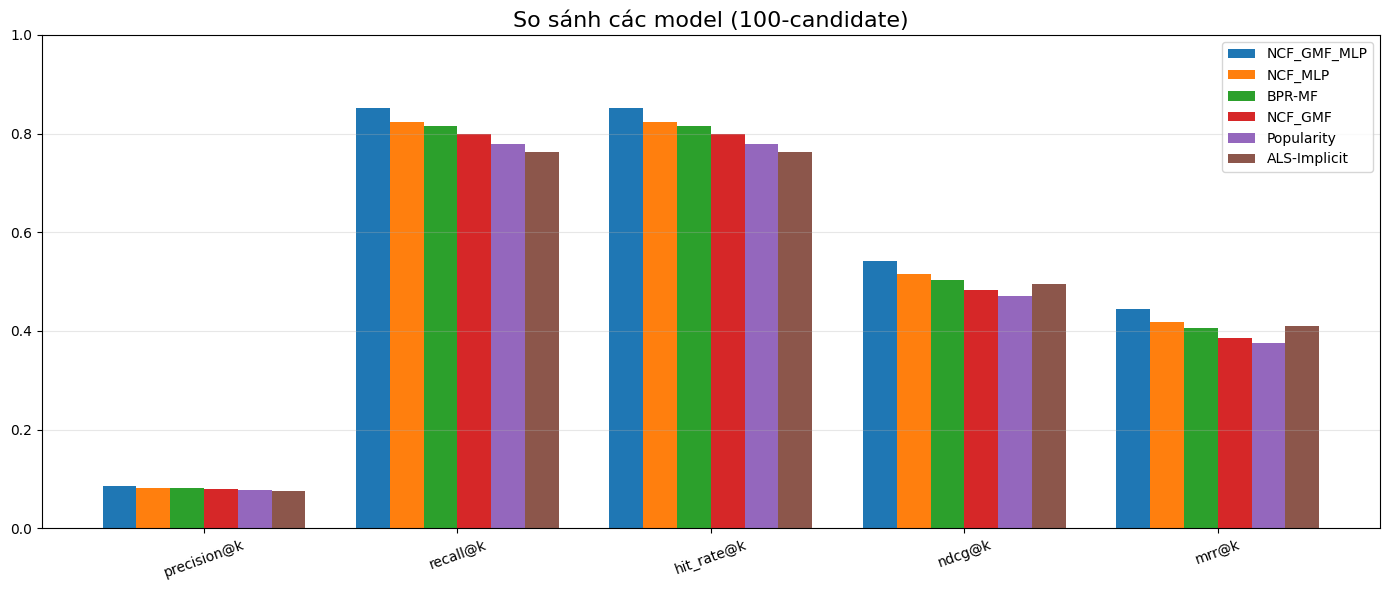


BẢNG B — FULL RANKING (2547 items, production-realistic, KHÓ HƠN)


,precision@k,recall@k,hit_rate@k,ndcg@k,mrr@k
Model,,,,,
NMF_GMF_MLP,0.0170,0.1702,0.1702,0.0887,0.0641
ALS-Implicit,0.0160,0.1601,0.1601,0.0776,0.0530
BPR-MF,0.0151,0.1506,0.1506,0.0774,0.0554
NCF_MLP,0.0140,0.1405,0.1405,0.0723,0.0518
Popularity,0.0137,0.1365,0.1365,0.0698,0.0499


[Saved] results_100cand.csv + results_full.csv
[Saved] ..\data\artifacts\cf\20261019_233722_1000000\20261019_233722_1000000_comparison_full.png


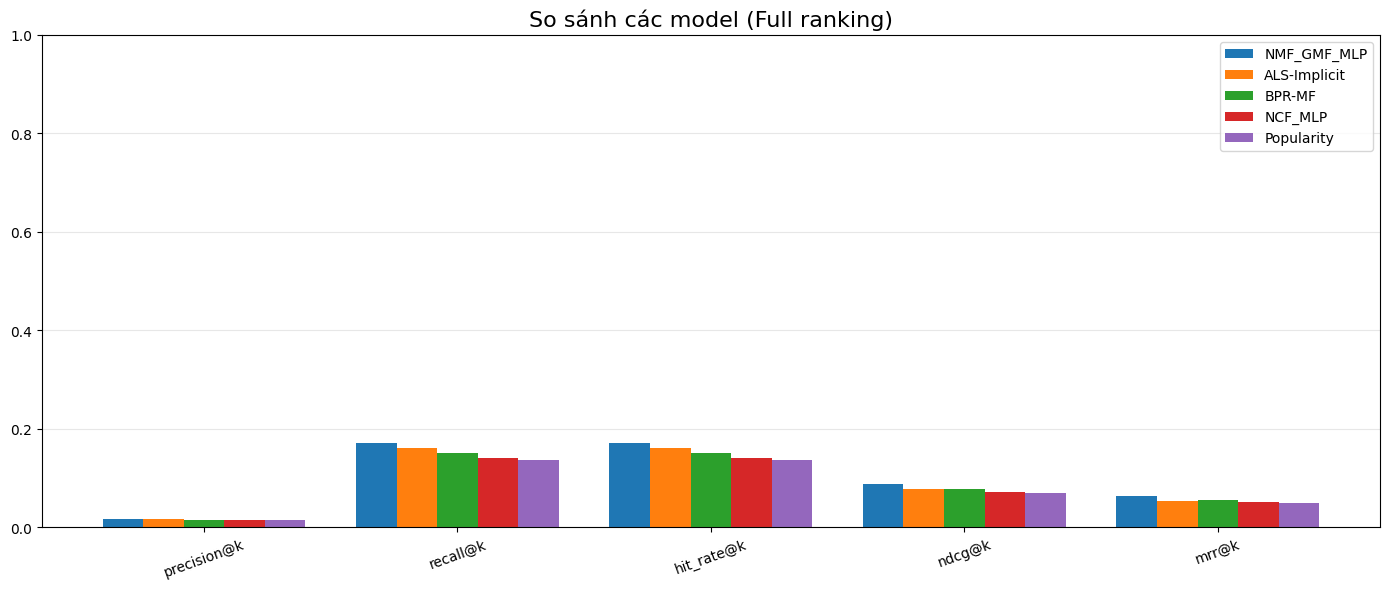

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Vẽ bar chart
def plot_model_comparison(title: str, df_compare: pd.DataFrame, dir_path_with_timestamp, filename="comparison.png"):
    metrics = ["precision@k","recall@k","f1@k","hit_rate@k","ndcg@k","mrr@k","map@k"]
    metrics = [m for m in metrics if m in df_compare.columns]
    x = np.arange(len(metrics)); w = 0.8/len(df_compare)
    fig, ax = plt.subplots(figsize=(14, 6))
    for i, model in enumerate(df_compare.index):
        ax.bar(x + (i - len(df_compare)/2 + 0.5)*w, df_compare.loc[model, metrics], w, label=model)
    ax.set_xticks(x); ax.set_xticklabels(metrics, rotation=20)
    ax.set_title(title, fontsize=16); ax.set_ylim(0, 1)
    ax.legend(); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    model_comparison_path = get_timestamped_path(dir_path_with_timestamp, filename)
    plt.savefig(model_comparison_path, dpi=150)
    print(f"[Saved] {model_comparison_path}")
    plt.show()


# Bảng 1: 100-candidate (paper-comparable)
rows_100 = []
for name, res in [
    ("Popularity",   pop_100),
    ("BPR-MF",       bpr_100),
    ("ALS-Implicit", als_100),
    ("NCF_GMF",       gmf_100),
    ("NCF_MLP",       mlp_100),
    # ("NCF_GMF",       gmf_ncf_100),
    # ("NCF_MLP",       mlp_ncf_100),
    ("NCF_GMF_MLP",  nmf_100),
]:
    rows_100.append({"Model": name,
                     **{k: v for k, v in res.items()
                        if k not in ("k", "n_users", "n_skipped")}})

df_100 = pd.DataFrame(rows_100).set_index("Model")
df_100 = df_100[["precision@k", "recall@k", "hit_rate@k", "ndcg@k", "mrr@k"]]
df_100 = df_100.round(4)
df_100 = df_100.sort_values("hit_rate@k", ascending=False)



# Bảng 2: Full ranking (production-realistic)
rows_full = []
for name, res in [
    ("Popularity",   pop_full),
    ("BPR-MF",       bpr_full),
    ("ALS-Implicit", als_full),
    ("NCF_MLP",          mlp_ncf_full),
    ("NCF_GMF",          gmf_ncf_full),
    ("NMF_GMF_MLP",  nmf_full),
]:
    rows_full.append({"Model": name,
                      **{k: v for k, v in res.items()
                         if k not in ("k", "n_users")}})

df_full = pd.DataFrame(rows_full).set_index("Model")
df_full = df_full[["precision@k", "recall@k", "hit_rate@k", "ndcg@k", "mrr@k"]]
df_full = df_full.round(4)
df_full = df_full.sort_values("hit_rate@k", ascending=False)


print("\n" + "="*90)
print("BẢNG A — 100-CANDIDATE PROTOCOL (SO SÁNH ĐƯỢC VỚI PAPER NCF)")
print("="*90)
display(df_100)
plot_model_comparison(
    title="So sánh các model (100-candidate)", 
    df_compare=df_100, 
    dir_path_with_timestamp=dir_path_with_timestamp,
    filename="comparison_100cand.png"
)

print("\n" + "="*90)
print("BẢNG B — FULL RANKING (2547 items, production-realistic, KHÓ HƠN)")
print("="*90)
display(df_full)

# Save
df_100.to_csv(get_timestamped_path(dir_path_with_timestamp, "results_100cand.csv"))
df_full.to_csv(get_timestamped_path(dir_path_with_timestamp, "results_full.csv"))
print("[Saved] results_100cand.csv + results_full.csv")

plot_model_comparison(
    title="So sánh các model (Full ranking)", 
    df_compare=df_full, 
    dir_path_with_timestamp=dir_path_with_timestamp,
    filename="comparison_full.png"
)


## Tỉnh chỉnh các mô hình để tối ưu tham số
- BPR

In [ ]:
def tune_bpr(grid, train_df, val_df, num_movies):
    results = []
    for cfg in grid:
        print(f"\n[Grid Search] Training BPR-MF with config: {cfg}")
        m = BPR_MF(num_users, num_movies, dim=cfg["dim"])
        
        tune_bpr_path = get_timestamped_path(dir_path_with_timestamp, f"tune_bpr_dim{cfg['dim']}_lr{cfg['lr']}.pt")
        
        # Val None để nhanh
        m = train_bpr_paper(m, train_df, num_movies, None,
                      epochs=cfg["epochs"], lr=cfg["lr"], batch_size=4096,
                      patience=2, ckpt_path=tune_bpr_path, seed=42)
        val_m = evaluate_recommender(m, val_df, train_df, k=10, verbose=False)
        results.append({**cfg, **{f"val_{k}":v for k,v in val_m.items() if k not in ("k","n_users")}})
        print(f"  → {cfg} | Val NDCG@10={val_m['ndcg@k']:.4f}")
        
    return pd.DataFrame(results).sort_values("val_ndcg@k", ascending=False)

# Ví dụ grid nhỏ — chạy hết khoảng 15–25 phút trên CPU
grid = [
    {"dim":32, "lr":1e-3, "epochs":10},
    {"dim":64, "lr":1e-3, "epochs":10},
    {"dim":64, "lr":2e-3, "epochs":10},
    {"dim":128,"lr":1e-3, "epochs":10},
]
df_tune = tune_bpr(grid, train_df, val_df, num_movies)
display(df_tune)